In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, json, random, copy
from pathlib import Path
import cv2, numpy as np, pandas as pd, torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT='/content/drive/MyDrive/Vessel_Merged'
OUT='/content/drive/MyDrive/DR_Project/RVS_normal_split_separate'
os.makedirs(OUT,exist_ok=True)
SIZE=512
BATCH=2
META=os.path.join(ROOT,'metadata.csv')
df=pd.read_csv(META)
assert {'image','mask','split'}.issubset(df.columns)
for c in ['image','mask']:
    df[c]=df[c].map(lambda p: str(p) if os.path.isabs(str(p)) else os.path.join(ROOT,str(p)))
    assert df[c].map(os.path.isfile).all(), f'Missing {c} files'
train_full=df[df.split.astype(str).str.lower()=='train'].reset_index(drop=True)
test_df=df[df.split.astype(str).str.lower()=='test'].reset_index(drop=True)
train_df,val_df=train_test_split(train_full,test_size=.20,random_state=SEED,shuffle=True)
train_df=train_df.reset_index(drop=True);val_df=val_df.reset_index(drop=True)
assert len(test_df)>0 and len(val_df)>0 and len(train_df)>=6
print('Train',len(train_df),'Val',len(val_df),'Test',len(test_df))

IMG_COL="image"
MSK_COL="mask"
assert len(train_df)+len(val_df)+len(test_df)==len(df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train 30 Val 8 Test 10


In [ ]:
IMG_SIZE = 512
USE_CLAHE = True

def apply_clahe_rgb(pil_img):
    img = np.array(pil_img)
    img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l2 = clahe.apply(l)

    lab2 = cv2.merge([l2, a, b])

    bgr2 = cv2.cvtColor(lab2, cv2.COLOR_LAB2BGR)
    rgb2 = cv2.cvtColor(bgr2, cv2.COLOR_BGR2RGB)

    return Image.fromarray(rgb2)


class VesselDataset(Dataset):
    def __init__(self, df, img_size=512, use_clahe=True):
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.use_clahe = use_clahe

    def __len__(self):
        return len(self.df)

    def _load_rgb(self, path):
        img = Image.open(path)
        img = img.convert("RGB")

        if self.use_clahe:
            img = apply_clahe_rgb(img)

        img = img.resize(
            (self.img_size, self.img_size),
            Image.BILINEAR
        )

        arr = np.array(img).astype(np.float32) / 255.0
        arr = np.transpose(arr, (2, 0, 1))

        return torch.tensor(arr, dtype=torch.float32)

    def _load_mask(self, path):
        m = Image.open(path)
        m = m.convert("L")

        m = m.resize(
            (self.img_size, self.img_size),
            Image.NEAREST
        )

        arr = np.array(m).astype(np.float32)
        arr = (arr > 127).astype(np.float32)

        arr = np.expand_dims(arr, axis=0)

        return torch.tensor(arr, dtype=torch.float32)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, IMG_COL]
        msk_path = self.df.loc[idx, MSK_COL]

        x = self._load_rgb(img_path)
        y = self._load_mask(msk_path)

        return x, y

In [ ]:
IMG_SIZE = 512
USE_CLAHE = True

def apply_clahe_rgb(pil_img):
    img = np.array(pil_img)
    img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l2 = clahe.apply(l)

    lab2 = cv2.merge([l2, a, b])

    bgr2 = cv2.cvtColor(lab2, cv2.COLOR_LAB2BGR)
    rgb2 = cv2.cvtColor(bgr2, cv2.COLOR_BGR2RGB)

    return Image.fromarray(rgb2)


class VesselDataset(Dataset):
    def __init__(self, df, img_size=512, use_clahe=True):
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.use_clahe = use_clahe

    def __len__(self):
        return len(self.df)

    def _load_rgb(self, path):
        img = Image.open(path)
        img = img.convert("RGB")

        if self.use_clahe:
            img = apply_clahe_rgb(img)

        img = img.resize(
            (self.img_size, self.img_size),
            Image.BILINEAR
        )

        arr = np.array(img).astype(np.float32) / 255.0
        arr = np.transpose(arr, (2, 0, 1))

        return torch.tensor(arr, dtype=torch.float32)

    def _load_mask(self, path):
        m = Image.open(path)
        m = m.convert("L")

        m = m.resize(
            (self.img_size, self.img_size),
            Image.NEAREST
        )

        arr = np.array(m).astype(np.float32)
        arr = (arr > 127).astype(np.float32)

        arr = np.expand_dims(arr, axis=0)

        return torch.tensor(arr, dtype=torch.float32)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, IMG_COL]
        msk_path = self.df.loc[idx, MSK_COL]

        x = self._load_rgb(img_path)
        y = self._load_mask(msk_path)

        return x, y

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class AttentionGate(nn.Module):

    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class AttUNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=64):
        super().__init__()
        # Encoder
        self.enc1 = DoubleConv(in_ch, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base*2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = DoubleConv(base*4, base*8)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(base*8, base*16)

        # Decoder
        self.up4 = nn.ConvTranspose2d(base*16, base*8, 2, stride=2)
        self.att4 = AttentionGate(base*8, base*8, base*4)
        self.dec4 = DoubleConv(base*16, base*8)

        self.up3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2)
        self.att3 = AttentionGate(base*4, base*4, base*2)
        self.dec3 = DoubleConv(base*8, base*4)

        self.up2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2)
        self.att2 = AttentionGate(base*2, base*2, base)
        self.dec2 = DoubleConv(base*4, base*2)

        self.up1 = nn.ConvTranspose2d(base*2, base, 2, stride=2)
        self.att1 = AttentionGate(base, base, base//2)
        self.dec1 = DoubleConv(base*2, base)

        self.out = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))

        b = self.bottleneck(self.pool4(e4))

        d4 = self.up4(b)
        e4a = self.att4(d4, e4)
        d4 = self.dec4(torch.cat([d4, e4a], dim=1))

        d3 = self.up3(d4)
        e3a = self.att3(d3, e3)
        d3 = self.dec3(torch.cat([d3, e3a], dim=1))

        d2 = self.up2(d3)
        e2a = self.att2(d2, e2)
        d2 = self.dec2(torch.cat([d2, e2a], dim=1))

        d1 = self.up1(d2)
        e1a = self.att1(d1, e1)
        d1 = self.dec1(torch.cat([d1, e1a], dim=1))

        return self.out(d1)

In [ ]:

# ============================================================
# DEFINE ATTENTION U-NET SEGMENTATION LOSS
# BCE + SOFT DICE LOSS
# ============================================================

import torch
import torch.nn as nn

# Binary Cross-Entropy Loss
bce_loss = nn.BCEWithLogitsLoss()

# Soft Dice Loss
class SoftDiceLoss(nn.Module):

    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        probabilities = torch.sigmoid(logits)

        probabilities = probabilities.reshape(
            probabilities.size(0), -1
        )

        targets = targets.reshape(
            targets.size(0), -1
        )

        intersection = (
            probabilities * targets
        ).sum(dim=1)

        denominator = (
            probabilities.sum(dim=1)
            + targets.sum(dim=1)
        )

        dice = (
            2 * intersection + self.smooth
        ) / (
            denominator + self.smooth
        )

        return 1 - dice.mean()


dice_loss = SoftDiceLoss()

# Combined segmentation loss
def criterion(logits, targets):

    loss_bce = bce_loss(logits, targets)

    loss_dice = dice_loss(logits, targets)

    return loss_bce + loss_dice


print("Attention U-Net loss function ready.")
print("Loss: BCEWithLogits + Soft Dice")


Attention U-Net loss function ready.
Loss: BCEWithLogits + Soft Dice


In [ ]:
# Train a SINGLE Attention U-Net, saving the best validation checkpoint.
import matplotlib.pyplot as plt
EPOCHS=100
PATIENCE=100
CHECKPOINT=os.path.join(OUT,'attention_unet_best.pth')
HISTORY=os.path.join(OUT,'attention_unet_history.csv')
train_loader=DataLoader(VesselDataset(train_df,SIZE,True),batch_size=BATCH,shuffle=True,num_workers=0)
val_loader=DataLoader(VesselDataset(val_df,SIZE,True),batch_size=1,num_workers=0)
model=AttUNet(in_ch=3,out_ch=1,base=64).to(device)
optimizer=torch.optim.Adam(model.parameters(),lr=1e-4)
rows=[];best=-1.;bad=0
@torch.no_grad()
def validate_attention(model,loader,threshold=0.5):
    model.eval();tp=fp=fn=0;loss_sum=0.;count=0
    for x,y in loader:
        x=x.to(device);y=y.to(device)
        logits=model(x);loss_sum+=criterion(logits,y).item()*len(x);count+=len(x)
        pred=torch.sigmoid(logits)>=threshold;gt=y>=.5
        tp+=int((pred&gt).sum());fp+=int((pred&~gt).sum());fn+=int((~pred&gt).sum())
    return loss_sum/max(count,1),2*tp/max(2*tp+fp+fn,1),tp/max(tp+fp+fn,1)
for epoch in range(1,EPOCHS+1):
    model.train();total=0.;count=0
    for x,y in tqdm(train_loader,desc=f'Attention U-Net {epoch}/{EPOCHS}'):
        x=x.to(device);y=y.to(device);optimizer.zero_grad(set_to_none=True)
        loss=criterion(model(x),y);loss.backward();optimizer.step()
        total+=loss.item()*len(x);count+=len(x)
    val_loss,val_dice,val_iou=validate_attention(model,val_loader)
    row={'epoch':epoch,'train_loss':total/max(count,1),'val_loss':val_loss,'val_dice_050':val_dice,'val_iou_050':val_iou}
    rows.append(row);pd.DataFrame(rows).to_csv(HISTORY,index=False)
    print(f'Epoch {epoch}: train loss={row["train_loss"]:.4f}, val loss={val_loss:.4f}, Dice={val_dice:.5f}, IoU={val_iou:.5f}')
    if val_dice>best+1e-6:
        best=val_dice;bad=0;torch.save(model.state_dict(),CHECKPOINT)
        print('Saved best Attention U-Net')
    else:bad+=1
    if bad>=PATIENCE:
        print('Early stopping');break
model.load_state_dict(torch.load(CHECKPOINT,map_location=device,weights_only=True));model.eval()
print('Best validation Dice @0.50:',best)

Attention U-Net 1/100:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1: train loss=1.3312, val loss=1.4546, Dice=0.00000, IoU=0.00000
Saved best Attention U-Net


Attention U-Net 2/100:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 2: train loss=1.1337, val loss=1.3221, Dice=0.00000, IoU=0.00000


Attention U-Net 3/100:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 3: train loss=1.0532, val loss=1.1421, Dice=0.37071, IoU=0.22753
Saved best Attention U-Net


... (190 outputs left out)

Attention U-Net 99/100:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 99: train loss=0.0705, val loss=0.4220, Dice=0.76840, IoU=0.62391


Attention U-Net 100/100:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 100: train loss=0.0690, val loss=0.4249, Dice=0.76705, IoU=0.62213
Best validation Dice @0.50: 0.7803865679777753


Recorded columns:
['epoch', 'train_loss', 'val_loss', 'val_dice_050', 'val_iou_050']


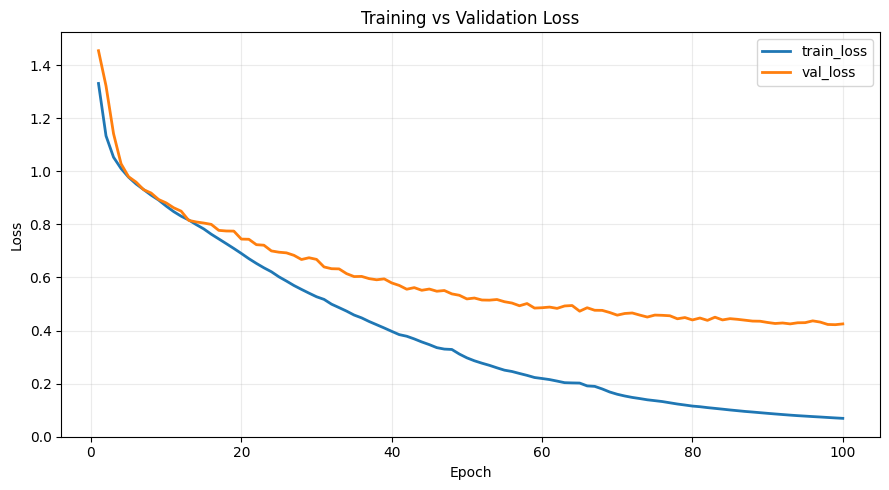

Saved: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/attention_unet_loss.png


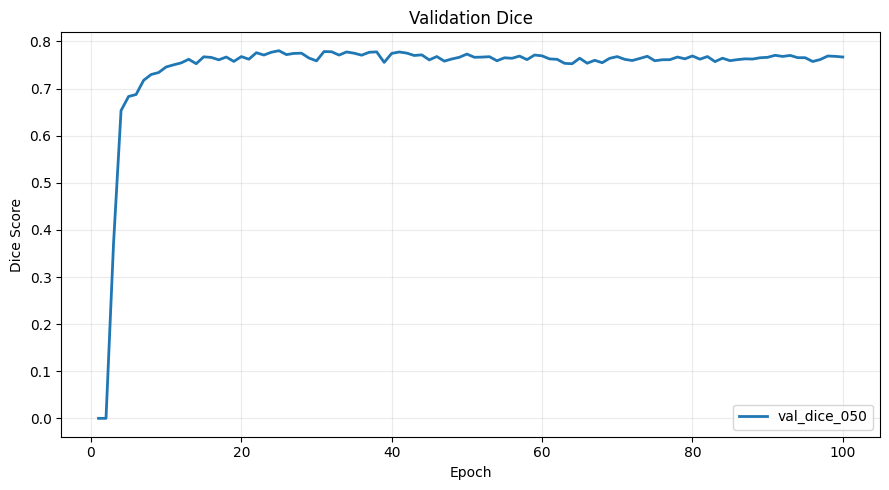

Saved: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/attention_unet_validation_dice.png


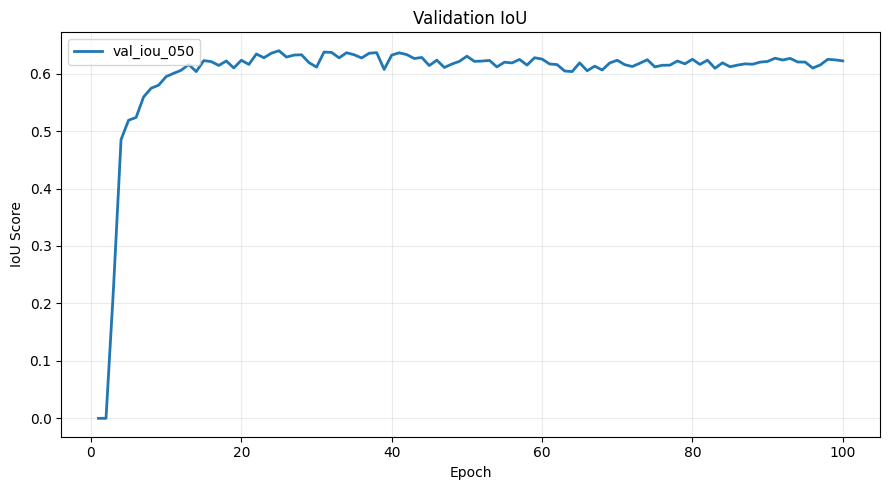

Saved: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/attention_unet_validation_iou.png

Note: Historical training Dice/IoU and separate BCE/Dice losses were not recorded by the current training loop.


In [ ]:

# ============================================================
# BLOCK 1 - ATTENTION U-NET TRAINING HISTORY PLOTS
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.read_csv(HISTORY)

os.makedirs(OUT, exist_ok=True)

print("Recorded columns:")
print(history_df.columns.tolist())

plots = [
    ("Training vs Validation Loss",
     ["train_loss", "val_loss"],
     "Loss",
     "attention_unet_loss.png"),

    ("Validation Dice",
     ["val_dice_050"],
     "Dice Score",
     "attention_unet_validation_dice.png"),

    ("Validation IoU",
     ["val_iou_050"],
     "IoU Score",
     "attention_unet_validation_iou.png")
]

for title, columns, ylabel, filename in plots:

    plt.figure(figsize=(9, 5))

    for col in columns:
        if col in history_df.columns:
            plt.plot(
                history_df["epoch"],
                history_df[col],
                linewidth=2,
                label=col
            )

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    path = os.path.join(OUT, filename)
    plt.savefig(path, dpi=300)
    plt.show()

    print("Saved:", path)

print(
    "\nNote: Historical training Dice/IoU and "
    "separate BCE/Dice losses were not recorded "
    "by the current training loop."
)


In [ ]:
# Choose a binary threshold using VALIDATION ONLY, never the test set.
thresholds=np.round(np.arange(.30,.701,.025),3)
val_scores=[(float(t),validate_attention(model,val_loader,float(t))[1]) for t in thresholds]
STAGE2_THRESHOLD=max(val_scores,key=lambda x:x[1])[0]
print('Validation-selected Stage 2 threshold:',STAGE2_THRESHOLD)
with open(os.path.join(OUT,'stage2_threshold.json'),'w') as f:
    json.dump({'stage2_threshold':STAGE2_THRESHOLD},f,indent=2)

Validation-selected Stage 2 threshold: 0.475


In [ ]:

# ============================================================
# BLOCK 2 - VALIDATION THRESHOLD SELECTION
# ============================================================

import numpy as np
import pandas as pd
import torch
import json

model.load_state_dict(
    torch.load(
        CHECKPOINT,
        map_location=device,
        weights_only=True
    )
)

model.eval()

@torch.no_grad()
def collect_predictions(model, loader):

    probabilities = []
    targets = []

    for x, y in loader:

        x = x.to(device)

        logits = model(x)

        prob = torch.sigmoid(
            logits
        ).cpu().numpy()

        probabilities.append(prob)
        targets.append(y.numpy())

    return (
        np.concatenate(probabilities, axis=0),
        np.concatenate(targets, axis=0)
    )


val_probs, val_targets = collect_predictions(
    model,
    val_loader
)

threshold_results = []

for threshold in np.arange(0.30, 0.701, 0.025):

    pred = val_probs >= threshold
    gt = val_targets >= 0.5

    tp = int((pred & gt).sum())
    fp = int((pred & ~gt).sum())
    fn = int((~pred & gt).sum())

    dice = 2 * tp / max(2 * tp + fp + fn, 1)
    iou = tp / max(tp + fp + fn, 1)

    threshold_results.append({
        "threshold": float(round(threshold, 3)),
        "dice": dice,
        "iou": iou
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.loc[
    threshold_df["dice"].idxmax()
]

SELECTED_THRESHOLD = float(
    best_row["threshold"]
)

print("Selected validation threshold:", SELECTED_THRESHOLD)
print("Validation Dice:", best_row["dice"])
print("Validation IoU:", best_row["iou"])

threshold_df.to_csv(
    os.path.join(OUT, "threshold_search.csv"),
    index=False
)

with open(
    os.path.join(OUT, "selected_threshold.json"),
    "w"
) as f:
    json.dump(
        {"selected_threshold": SELECTED_THRESHOLD},
        f,
        indent=2
    )


Selected validation threshold: 0.475
Validation Dice: 0.7804785873690726
Validation IoU: 0.6399876043876194


In [ ]:

# ============================================================
# BLOCK 3 - FINAL SEGMENTATION METRICS
# ============================================================

import numpy as np
import pandas as pd
import torch

test_loader = DataLoader(
    VesselDataset(test_df, SIZE, True),
    batch_size=1,
    shuffle=False,
    num_workers=0
)

@torch.no_grad()
def evaluate_segmentation(model, loader, threshold):

    model.eval()

    TP = FP = FN = TN = 0
    loss_sum = 0.0
    count = 0

    for x, y in loader:

        x = x.to(device)
        y = y.to(device)

        logits = model(x)

        loss = criterion(logits, y)

        loss_sum += loss.item() * len(x)
        count += len(x)

        pred = torch.sigmoid(logits) >= threshold
        gt = y >= 0.5

        TP += int((pred & gt).sum().item())
        FP += int((pred & ~gt).sum().item())
        FN += int((~pred & gt).sum().item())
        TN += int((~pred & ~gt).sum().item())

    dice = 2 * TP / max(2 * TP + FP + FN, 1)
    iou = TP / max(TP + FP + FN, 1)
    precision = TP / max(TP + FP, 1)
    recall = TP / max(TP + FN, 1)
    accuracy = (
        (TP + TN) /
        max(TP + TN + FP + FN, 1)
    )

    return {
        "loss": loss_sum / max(count, 1),
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "accuracy": accuracy,
        "tp": TP,
        "fp": FP,
        "fn": FN,
        "tn": TN
    }


train_results = evaluate_segmentation(
    model, train_loader, SELECTED_THRESHOLD
)

val_results = evaluate_segmentation(
    model, val_loader, SELECTED_THRESHOLD
)

test_results = evaluate_segmentation(
    model, test_loader, SELECTED_THRESHOLD
)

results_df = pd.DataFrame([
    {"split": "train", **train_results},
    {"split": "validation", **val_results},
    {"split": "test", **test_results}
])

print("\nFINAL ATTENTION U-NET RESULTS")
print(results_df.to_string(index=False))

results_df.to_csv(
    os.path.join(OUT, "attention_unet_final_metrics.csv"),
    index=False
)



FINAL ATTENTION U-NET RESULTS
     split     loss     dice      iou  precision   recall  accuracy     tp     fp    fn      tn
     train 0.599280 0.874560 0.777083   0.822405 0.933778  0.979935 550082 118788 39011 7156439
validation 0.695185 0.780479 0.639988   0.769352 0.791931  0.967870 119782  35910 31471 1909989
      test 0.679373 0.777804 0.636398   0.761339 0.794996  0.961671 175861  55128 45349 2345102


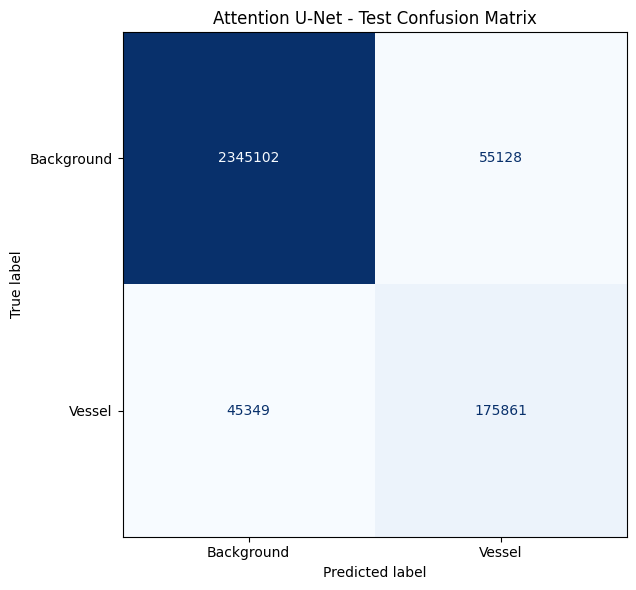

TN: 2345102
FP: 55128
FN: 45349
TP: 175861
Saved: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/attention_unet_test_confusion_matrix.png


In [ ]:

# ============================================================
# BLOCK 4 - TEST CONFUSION MATRIX
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = np.array([
    [test_results["tn"], test_results["fp"]],
    [test_results["fn"], test_results["tp"]]
])

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Background", "Vessel"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Attention U-Net - Test Confusion Matrix")
plt.tight_layout()

save_path = os.path.join(
    OUT,
    "attention_unet_test_confusion_matrix.png"
)

plt.savefig(save_path, dpi=300)
plt.show()

print("TN:", test_results["tn"])
print("FP:", test_results["fp"])
print("FN:", test_results["fn"])
print("TP:", test_results["tp"])
print("Saved:", save_path)


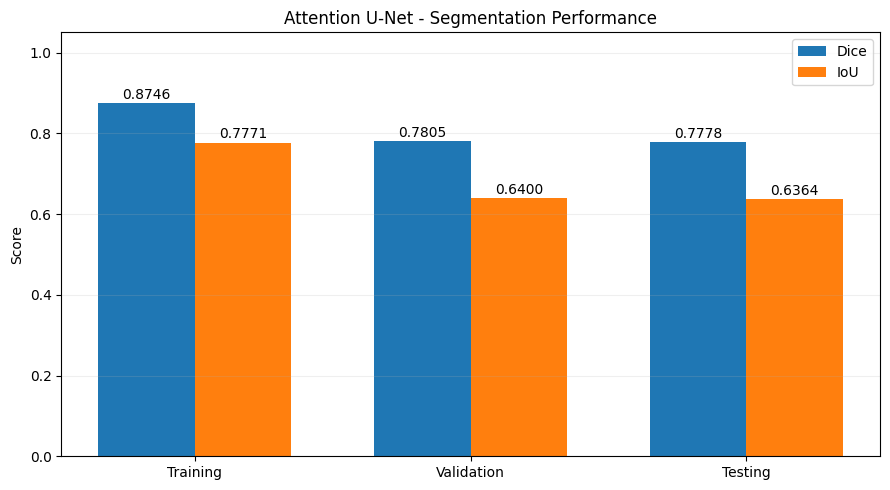

Saved: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/attention_unet_dice_iou_comparison.png


In [ ]:

# ============================================================
# BLOCK 5 - TRAIN / VALIDATION / TEST METRIC COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

labels = ["Training", "Validation", "Testing"]

dice_values = [
    train_results["dice"],
    val_results["dice"],
    test_results["dice"]
]

iou_values = [
    train_results["iou"],
    val_results["iou"],
    test_results["iou"]
]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(
    x - width / 2,
    dice_values,
    width,
    label="Dice"
)

bars2 = ax.bar(
    x + width / 2,
    iou_values,
    width,
    label="IoU"
)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{bar.get_height():.4f}",
            ha="center"
        )

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Attention U-Net - Segmentation Performance")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

save_path = os.path.join(
    OUT,
    "attention_unet_dice_iou_comparison.png"
)

plt.savefig(save_path, dpi=300)
plt.show()

print("Saved:", save_path)


In [ ]:
# Export exactly one prediction per image, preserving split and original identity.
# All saved RGB and GT files are resized to 512x512 for direct alignment.
import re
PRED_ROOT=os.path.join(OUT,'saved_predictions')
records=[]
split_frames={'train':train_df,'val':val_df,'test':test_df}
@torch.inference_mode()
def export_split(split,frame):
    model.eval();ds=VesselDataset(frame,SIZE,True)
    subdirs={k:os.path.join(PRED_ROOT,split,k) for k in ['rgb','probability','binary','ground_truth']}
    for path in subdirs.values():os.makedirs(path,exist_ok=True)
    for i in tqdm(range(len(ds)),desc=f'Export {split}'):
        row=frame.iloc[i];x,y=ds[i]
        prob=torch.sigmoid(model(x[None].to(device)))[0,0].cpu().numpy().astype('float32')
        source=str(row['source']) if 'source' in frame.columns else 'RVS'
        clean=re.sub(r'[^A-Za-z0-9_-]','_',source)
        image_id=Path(str(row['image'])).stem
        uid=f'{split}_{clean}_{image_id}_{i:04d}'
        rgb_path=os.path.join(subdirs['rgb'],uid+'.png')
        prob_path=os.path.join(subdirs['probability'],uid+'.npy')
        binary_path=os.path.join(subdirs['binary'],uid+'.png')
        gt_path=os.path.join(subdirs['ground_truth'],uid+'.png')
        with Image.open(row['image']) as im:
            im.convert('RGB').resize((SIZE,SIZE),Image.Resampling.BILINEAR).save(rgb_path)
        np.save(prob_path,prob)
        cv2.imwrite(binary_path,(prob>=STAGE2_THRESHOLD).astype('uint8')*255)
        cv2.imwrite(gt_path,(y[0].numpy()>=.5).astype('uint8')*255)
        records.append({'id':uid,'split':split,'source':source,'original_image_path':str(row['image']),
                        'rgb_path':rgb_path,'probability_path':prob_path,'binary_path':binary_path,
                        'ground_truth':gt_path,'original_ground_truth_path':str(row['mask'])})
for split,frame in split_frames.items():export_split(split,frame)
manifest_df=pd.DataFrame(records)
MANIFEST=os.path.join(OUT,'prediction_manifest.csv')
manifest_df.to_csv(MANIFEST,index=False)
assert len(manifest_df)==len(df),f'Exported {len(manifest_df)} records, expected {len(df)}'
assert manifest_df['id'].is_unique
for col in ['rgb_path','probability_path','binary_path','ground_truth']:
    assert manifest_df[col].map(os.path.isfile).all(),f'Missing {col}'
print('Exported',len(manifest_df),'of',len(df),'records')
print(manifest_df['split'].value_counts().to_string())
print('Manifest:',MANIFEST)

Export train:   0%|          | 0/30 [00:00<?, ?it/s]

Export val:   0%|          | 0/8 [00:00<?, ?it/s]

Export test:   0%|          | 0/10 [00:00<?, ?it/s]

Exported 48 of 48 records
split
train    30
test     10
val       8
Manifest: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/prediction_manifest.csv


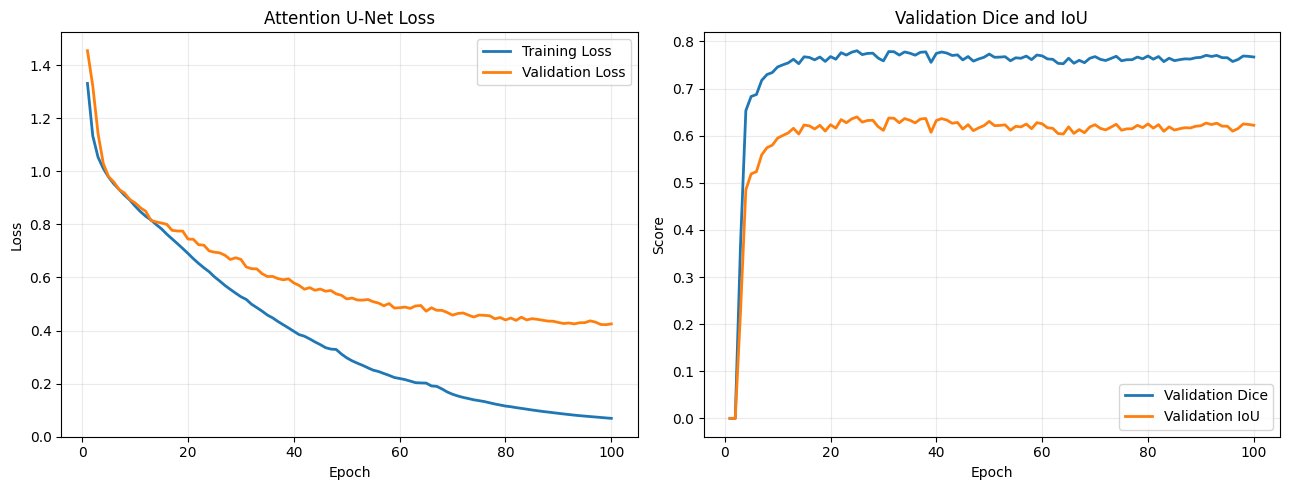

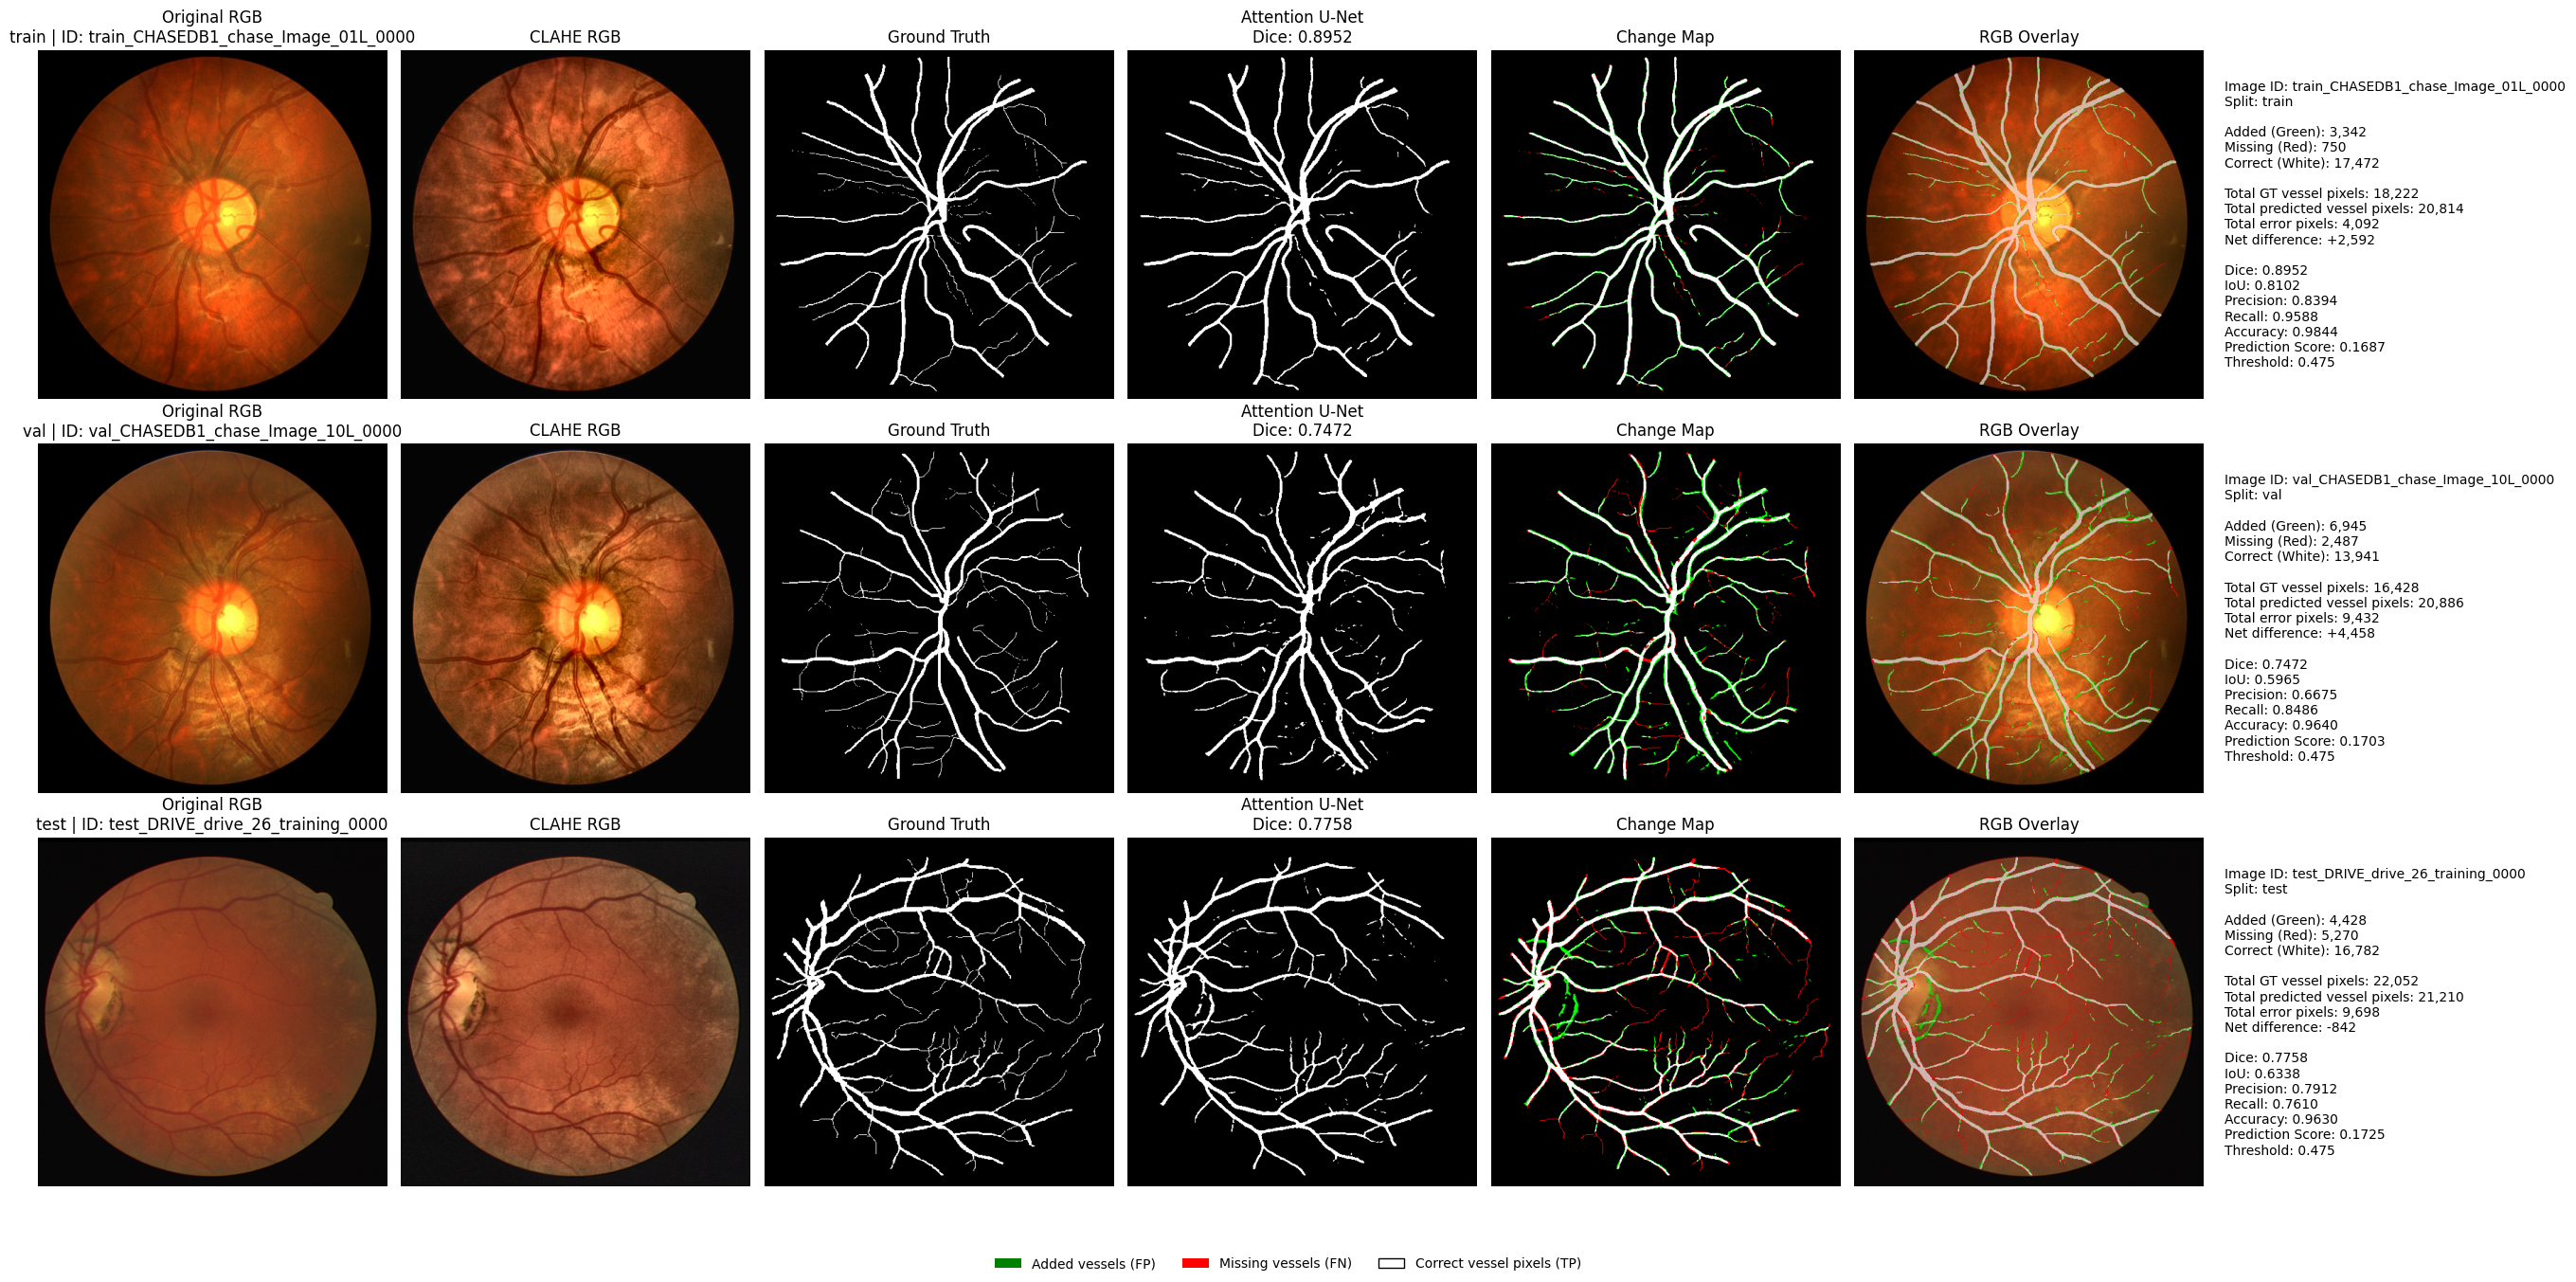


ATTENTION U-NET IMAGE RESULTS
split                            image_id  added_pixels_fp  missing_pixels_fn  correct_vessel_pixels_tp  correct_background_pixels_tn  total_ground_truth_vessel_pixels  total_predicted_vessel_pixels  total_error_pixels  net_difference     dice      iou  precision   recall  accuracy  mean_vessel_probability  threshold
train train_CHASEDB1_chase_Image_01L_0000             3342                750                     17472                        240580                             18222                          20814                4092            2592 0.895174 0.810239   0.839435 0.958841  0.984390                 0.168747      0.475
  val   val_CHASEDB1_chase_Image_10L_0000             6945               2487                     13941                        238771                             16428                          20886                9432            4458 0.747226 0.596457   0.667481 0.848612  0.964020                 0.170287      0.475
 test   test

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from matplotlib.patches import Patch

os.makedirs(OUT, exist_ok=True)



h = pd.read_csv(HISTORY)

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

axes[0].plot(
    h["epoch"],
    h["train_loss"],
    label="Training Loss",
    linewidth=2
)

axes[0].plot(
    h["epoch"],
    h["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[0].set_title("Attention U-Net Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    h["epoch"],
    h["val_dice_050"],
    label="Validation Dice",
    linewidth=2
)

axes[1].plot(
    h["epoch"],
    h["val_iou_050"],
    label="Validation IoU",
    linewidth=2
)

axes[1].set_title("Validation Dice and IoU")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT,
        "attention_training_plots.png"
    ),
    dpi=300
)

plt.show()




def apply_clahe_for_display(pil_img):

    rgb = np.asarray(
        pil_img.convert("RGB")
    )

    lab = cv2.cvtColor(
        rgb,
        cv2.COLOR_RGB2LAB
    )

    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l)

    enhanced = cv2.cvtColor(
        cv2.merge((enhanced_l, a, b)),
        cv2.COLOR_LAB2RGB
    )

    return enhanced




# Use the threshold selected on validation.
if "SELECTED_THRESHOLD" in globals():
    MASK_THRESHOLD = float(SELECTED_THRESHOLD)
else:
    MASK_THRESHOLD = 0.50
    print(
        "Using threshold 0.50 because "
        "SELECTED_THRESHOLD is unavailable."
    )

examples = []

for split in ["train", "val", "test"]:

    subset = manifest_df[
        manifest_df["split"] == split
    ]

    if subset.empty:
        raise ValueError(
            f"No saved predictions for {split}"
        )

    examples.append(
        (split, subset.iloc[0])
    )

fig, axes = plt.subplots(
    len(examples),
    7,
    figsize=(28, 4.5 * len(examples)),
    squeeze=False
)

results = []

for j, (split, row) in enumerate(examples):

    image_id = str(row["id"])



    with Image.open(row["rgb_path"]) as im:

        original_rgb = np.asarray(
            im.convert("RGB")
        )

        clahe_rgb_image = apply_clahe_for_display(im)

    height, width = original_rgb.shape[:2]

    # --------------------------------------------------------
    # GROUND TRUTH
    # --------------------------------------------------------

    with Image.open(row["ground_truth"]) as im:

        gt = np.asarray(
            im.convert("L")
        ) > 127

    # --------------------------------------------------------
    # LOAD SAVED ATTENTION U-NET PROBABILITY MASK
    # --------------------------------------------------------

    probability = np.load(
        row["probability_path"]
    ).astype(np.float32)

    if probability.ndim == 3:
        probability = np.squeeze(probability)

    if probability.shape != gt.shape:
        raise ValueError(
            f"Mask shape mismatch for {image_id}: "
            f"{probability.shape} vs {gt.shape}"
        )

    predicted = (
        probability >= MASK_THRESHOLD
    )

    # --------------------------------------------------------
    # CHANGE MAP - PREDICTION VS GROUND TRUTH
    # --------------------------------------------------------

    added = predicted & ~gt
    removed = gt & ~predicted
    matched = predicted & gt
    background = ~predicted & ~gt

    change_map = np.zeros(
        (height, width, 3),
        dtype=np.uint8
    )

    change_map[matched] = [255, 255, 255]
    change_map[added] = [0, 255, 0]
    change_map[removed] = [255, 0, 0]

    # --------------------------------------------------------
    # RGB OVERLAY
    # --------------------------------------------------------

    overlay = original_rgb.copy()

    alpha = 0.65

    for mask, color in [
        (matched, [255, 255, 255]),
        (added, [0, 255, 0]),
        (removed, [255, 0, 0])
    ]:

        overlay[mask] = (
            (1 - alpha) * overlay[mask].astype(float)
            + alpha * np.asarray(color)
        ).astype(np.uint8)

    # --------------------------------------------------------
    # PIXEL COUNTS
    # --------------------------------------------------------

    tp = int(matched.sum())
    fp = int(added.sum())
    fn = int(removed.sum())
    tn = int(background.sum())

    total_predicted = int(predicted.sum())
    total_ground_truth = int(gt.sum())

    total_errors = fp + fn

    net_difference = (
        total_predicted - total_ground_truth
    )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    dice = 2 * tp / max(2 * tp + fp + fn, 1)
    iou = tp / max(tp + fp + fn, 1)

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)

    accuracy = (
        (tp + tn) /
        max(tp + tn + fp + fn, 1)
    )

    prediction_score = float(
        probability.mean()
    )

    # --------------------------------------------------------
    # DISPLAY
    # --------------------------------------------------------

    axes[j, 0].imshow(original_rgb)
    axes[j, 0].set_title(
        f"Original RGB\n{split} | ID: {image_id}"
    )

    axes[j, 1].imshow(clahe_rgb_image)
    axes[j, 1].set_title("CLAHE RGB")

    axes[j, 2].imshow(
        gt,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[j, 2].set_title("Ground Truth")

    axes[j, 3].imshow(
        predicted,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[j, 3].set_title(
        f"Attention U-Net\nDice: {dice:.4f}"
    )

    axes[j, 4].imshow(change_map)
    axes[j, 4].set_title("Change Map")

    axes[j, 5].imshow(overlay)
    axes[j, 5].set_title("RGB Overlay")

    axes[j, 6].axis("off")

    statistics = (
        f"Image ID: {image_id}\n"
        f"Split: {split}\n\n"
        f"Added (Green): {fp:,}\n"
        f"Missing (Red): {fn:,}\n"
        f"Correct (White): {tp:,}\n\n"
        f"Total GT vessel pixels: {total_ground_truth:,}\n"
        f"Total predicted vessel pixels: {total_predicted:,}\n"
        f"Total error pixels: {total_errors:,}\n"
        f"Net difference: {net_difference:+,}\n\n"
        f"Dice: {dice:.4f}\n"
        f"IoU: {iou:.4f}\n"
        f"Precision: {precision:.4f}\n"
        f"Recall: {recall:.4f}\n"
        f"Accuracy: {accuracy:.4f}\n"
        f"Prediction Score: {prediction_score:.4f}\n"
        f"Threshold: {MASK_THRESHOLD:.3f}"
    )

    axes[j, 6].text(
        0.02,
        0.5,
        statistics,
        fontsize=10,
        va="center",
        ha="left",
        transform=axes[j, 6].transAxes
    )

    for col in range(6):
        axes[j, col].axis("off")

    results.append({
        "split": split,
        "image_id": image_id,
        "added_pixels_fp": fp,
        "missing_pixels_fn": fn,
        "correct_vessel_pixels_tp": tp,
        "correct_background_pixels_tn": tn,
        "total_ground_truth_vessel_pixels": total_ground_truth,
        "total_predicted_vessel_pixels": total_predicted,
        "total_error_pixels": total_errors,
        "net_difference": net_difference,
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "accuracy": accuracy,
        "mean_vessel_probability": prediction_score,
        "threshold": MASK_THRESHOLD
    })

# ============================================================
# PART 4 - LEGEND
# ============================================================

legend_items = [
    Patch(facecolor="green", label="Added vessels (FP)"),
    Patch(facecolor="red", label="Missing vessels (FN)"),
    Patch(
        facecolor="white",
        edgecolor="black",
        label="Correct vessel pixels (TP)"
    )
]

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=3,
    frameon=False
)

plt.tight_layout(
    rect=[0, 0.05, 1, 1]
)

# ============================================================
# PART 5 - SAVE RESULTS
# ============================================================

figure_path = os.path.join(
    OUT,
    "attention_unet_change_maps.png"
)

csv_path = os.path.join(
    OUT,
    "attention_unet_image_statistics.csv"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

results_df = pd.DataFrame(results)

results_df.to_csv(
    csv_path,
    index=False
)

print("\nATTENTION U-NET IMAGE RESULTS")
print(results_df.to_string(index=False))

print("\nSaved figure:", figure_path)
print("Saved CSV:", csv_path)


In [ ]:

# ============================================================
# SAVE RGB IMAGES + PREDICTED VESSEL MASKS
# 48 RVS IMAGES - TRAIN / VALIDATION / TEST
# ============================================================

import os
import shutil
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

ROOT = (
    "/content/drive/MyDrive/DR_Project/"
    "RVS_normal_split_separate"
)

MANIFEST = os.path.join(
    ROOT,
    "prediction_manifest.csv"
)

SAVE_ROOT = os.path.join(
    ROOT,
    "RGB_Predicted_Masks"
)

df = pd.read_csv(MANIFEST)

required = [
    "id",
    "split",
    "rgb_path",
    "binary_path",
    "probability_path",
    "ground_truth"
]

for col in required:
    if col not in df.columns:
        raise ValueError(f"Missing column: {col}")

records = []

for split in ["train", "val", "test"]:

    subset = df[
        df["split"] == split
    ].reset_index(drop=True)

    rgb_dir = os.path.join(
        SAVE_ROOT, split, "RGB"
    )

    mask_dir = os.path.join(
        SAVE_ROOT, split, "Predicted_Masks"
    )

    prob_dir = os.path.join(
        SAVE_ROOT, split, "Probability_Masks"
    )

    for folder in [rgb_dir, mask_dir, prob_dir]:
        os.makedirs(folder, exist_ok=True)

    for _, row in tqdm(
        subset.iterrows(),
        total=len(subset),
        desc=f"Saving {split}"
    ):

        image_id = str(row["id"])

        rgb_source = str(row["rgb_path"])
        mask_source = str(row["binary_path"])
        prob_source = str(row["probability_path"])

        rgb_dest = os.path.join(
            rgb_dir, image_id + ".png"
        )

        mask_dest = os.path.join(
            mask_dir, image_id + "_pred.png"
        )

        prob_dest = os.path.join(
            prob_dir, image_id + ".npy"
        )

        for source, dest in [
            (rgb_source, rgb_dest),
            (mask_source, mask_dest),
            (prob_source, prob_dest)
        ]:

            if not os.path.isfile(source):
                raise FileNotFoundError(source)

            if os.path.abspath(source) != os.path.abspath(dest):
                shutil.copy2(source, dest)

        records.append({
            "image_id": image_id,
            "split": split,
            "rgb_path": rgb_dest,
            "predicted_mask_path": mask_dest,
            "probability_path": prob_dest,
            "ground_truth": row["ground_truth"]
        })

# ------------------------------------------------------------
# SAVE UPDATED MANIFEST
# ------------------------------------------------------------

saved_df = pd.DataFrame(records)

CSV_PATH = os.path.join(
    SAVE_ROOT,
    "rgb_predicted_mask_manifest.csv"
)

saved_df.to_csv(CSV_PATH, index=False)

print("\n" + "=" * 60)
print("RGB + PREDICTED MASK EXPORT COMPLETED")
print("=" * 60)

print("Total paired images:", len(saved_df))
print(saved_df["split"].value_counts())

print("\nSaved folder:", SAVE_ROOT)
print("Manifest:", CSV_PATH)

assert len(saved_df) == len(df)
assert saved_df["rgb_path"].map(os.path.isfile).all()
assert saved_df["predicted_mask_path"].map(os.path.isfile).all()
assert saved_df["probability_path"].map(os.path.isfile).all()


Saving train:   0%|          | 0/30 [00:00<?, ?it/s]

Saving val:   0%|          | 0/8 [00:00<?, ?it/s]

Saving test:   0%|          | 0/10 [00:00<?, ?it/s]


RGB + PREDICTED MASK EXPORT COMPLETED
Total paired images: 48
split
train    30
test     10
val       8
Name: count, dtype: int64

Saved folder: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/RGB_Predicted_Masks
Manifest: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/RGB_Predicted_Masks/rgb_predicted_mask_manifest.csv


In [ ]:

# ============================================================
# BLOCK 1 - DR2015 SETUP AND LOCAL RGB COPY
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import cv2
import shutil
import numpy as np
import pandas as pd
import torch

from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

DRIVE_RGB_ROOT = (
    "/content/drive/MyDrive/"
    "Dataset/colored_images/colored_images"
)

LOCAL_RGB_ROOT = "/content/dr2015_rgb_local"

OUTPUT_ROOT = (
    "/content/drive/MyDrive/DR_Project/"
    "DR2015_Untitled3_Masks"
)

CLASS_FOLDERS = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferate_DR"
]

VALID_EXTENSIONS = (".png", ".jpg", ".jpeg")

if not os.path.isdir(DRIVE_RGB_ROOT):
    raise FileNotFoundError(DRIVE_RGB_ROOT)

jobs = []

for folder in CLASS_FOLDERS:

    src_dir = os.path.join(DRIVE_RGB_ROOT, folder)
    dst_dir = os.path.join(LOCAL_RGB_ROOT, folder)

    if not os.path.isdir(src_dir):
        raise FileNotFoundError(src_dir)

    os.makedirs(dst_dir, exist_ok=True)
    os.makedirs(
        os.path.join(OUTPUT_ROOT, folder),
        exist_ok=True
    )

    for filename in os.listdir(src_dir):

        if filename.lower().endswith(VALID_EXTENSIONS):

            jobs.append((
                os.path.join(src_dir, filename),
                os.path.join(dst_dir, filename)
            ))

print("Images to copy:", len(jobs))

def copy_image(job):

    src, dst = job

    if (
        os.path.isfile(dst)
        and os.path.getsize(dst) == os.path.getsize(src)
    ):
        return

    temp = dst + ".tmp"
    shutil.copyfile(src, temp)
    os.replace(temp, dst)

with ThreadPoolExecutor(max_workers=8) as pool:

    list(tqdm(
        pool.map(copy_image, jobs),
        total=len(jobs),
        desc="Copying DR2015 RGB images"
    ))

print("Local RGB copy completed.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Images to copy: 35126


Copying DR2015 RGB images:   0%|          | 0/35126 [00:00<?, ?it/s]

Local RGB copy completed.


In [ ]:

# ============================================================
# BLOCK 2 - LOAD TRAINED ATTENTION U-NET
# ============================================================

import os
import json
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_ROOT = (
    "/content/drive/MyDrive/DR_Project/"
    "RVS_normal_split_separate"
)

CHECKPOINT = os.path.join(
    MODEL_ROOT,
    "attention_unet_best.pth"
)

THRESHOLD_FILE = os.path.join(
    MODEL_ROOT,
    "selected_threshold.json"
)

if not os.path.isfile(CHECKPOINT):
    raise FileNotFoundError(CHECKPOINT)

if not os.path.isfile(THRESHOLD_FILE):
    raise FileNotFoundError(
        "Validation-selected threshold file missing: "
        + THRESHOLD_FILE
    )

with open(THRESHOLD_FILE, "r") as f:
    threshold_data = json.load(f)

SELECTED_THRESHOLD = float(
    threshold_data["selected_threshold"]
)

model = AttUNet(
    in_ch=3,
    out_ch=1,
    base=64
).to(device)

model.load_state_dict(
    torch.load(
        CHECKPOINT,
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Attention U-Net loaded.")
print("Threshold:", SELECTED_THRESHOLD)
print("Device:", device)


Attention U-Net loaded.
Threshold: 0.475
Device: cuda


In [ ]:

# ============================================================
# BLOCK 3 - GENERATE DR2015 VESSEL MASKS
# ONLY BINARY MASKS, ORGANIZED BY SEVERITY
# ============================================================

import cv2
import numpy as np
import torch
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm

SIZE = 512

def preprocess_rgb(pil_img):

    rgb = np.asarray(
        pil_img.convert("RGB")
    )

    lab = cv2.cvtColor(
        rgb,
        cv2.COLOR_RGB2LAB
    )

    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l = clahe.apply(l)

    enhanced = cv2.cvtColor(
        cv2.merge((l, a, b)),
        cv2.COLOR_LAB2RGB
    )

    enhanced = cv2.resize(
        enhanced,
        (SIZE, SIZE),
        interpolation=cv2.INTER_LINEAR
    )

    tensor = torch.from_numpy(
        np.ascontiguousarray(
            enhanced.transpose(2, 0, 1)
        )
    ).float() / 255.0

    return tensor


model.eval()

total_saved = 0

for folder in CLASS_FOLDERS:

    input_folder = os.path.join(
        LOCAL_RGB_ROOT, folder
    )

    output_folder = os.path.join(
        OUTPUT_ROOT, folder
    )

    image_files = sorted([
        f for f in os.listdir(input_folder)
        if f.lower().endswith(VALID_EXTENSIONS)
    ])

    print(f"\nProcessing {folder}: {len(image_files)} images")

    for filename in tqdm(
        image_files,
        desc=f"Predicting {folder}"
    ):

        image_path = os.path.join(
            input_folder, filename
        )

        image_id = Path(filename).stem

        mask_path = os.path.join(
            output_folder,
            image_id + ".png"
        )

        if os.path.isfile(mask_path):
            total_saved += 1
            continue

        with Image.open(image_path) as im:
            x = preprocess_rgb(im)

        x = x.unsqueeze(0).to(device)

        with torch.inference_mode():

            logits = model(x)

            probability = torch.sigmoid(
                logits
            )[0, 0].cpu().numpy()

        mask = (
            probability >= SELECTED_THRESHOLD
        ).astype(np.uint8) * 255

        success = cv2.imwrite(mask_path, mask)

        if not success:
            raise IOError(
                "Could not save mask: " + mask_path
            )

        total_saved += 1

    print(folder, "completed.")

print("\nTOTAL MASKS SAVED:", total_saved)
print("Output:", OUTPUT_ROOT)



Processing No_DR: 25810 images


Predicting No_DR:   0%|          | 0/25810 [00:00<?, ?it/s]

No_DR completed.

Processing Mild: 2443 images


Predicting Mild:   0%|          | 0/2443 [00:00<?, ?it/s]

Mild completed.

Processing Moderate: 5292 images


Predicting Moderate:   0%|          | 0/5292 [00:00<?, ?it/s]

Moderate completed.

Processing Severe: 873 images


Predicting Severe:   0%|          | 0/873 [00:00<?, ?it/s]

Severe completed.

Processing Proliferate_DR: 708 images


Predicting Proliferate_DR:   0%|          | 0/708 [00:00<?, ?it/s]

Proliferate_DR completed.

TOTAL MASKS SAVED: 35126
Output: /content/drive/MyDrive/DR_Project/DR2015_Untitled3_Masks


In [ ]:

# ============================================================
# BLOCK 4 - VERIFY DR2015 MASK OUTPUT
# ============================================================

total = 0

for folder in CLASS_FOLDERS:

    input_folder = os.path.join(
        LOCAL_RGB_ROOT, folder
    )

    output_folder = os.path.join(
        OUTPUT_ROOT, folder
    )

    expected = len([
        f for f in os.listdir(input_folder)
        if f.lower().endswith(VALID_EXTENSIONS)
    ])

    actual = len([
        f for f in os.listdir(output_folder)
        if f.lower().endswith(".png")
    ])

    print(
        f"{folder}: {actual:,}/{expected:,} masks"
    )

    if actual != expected:
        raise RuntimeError(
            f"Incomplete masks for {folder}"
        )

    total += actual

print("\nALL FOLDERS VERIFIED")
print("Total masks:", total)


No_DR: 25,810/25,810 masks
Mild: 2,443/2,443 masks
Moderate: 5,292/5,292 masks
Severe: 873/873 masks
Proliferate_DR: 708/708 masks

ALL FOLDERS VERIFIED
Total masks: 35126
